# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
#print(f"matplotib version: {plt.__version__}")
print(f"seaborn version: {sns.__version__}")

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
seaborn version: 0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:


S = np.array([[10,4],[2,1],[7,3],[1,2]])
theta = np.array([0.3,0.7])
bias = 0.5


z = S @ theta + bias
print("z =", z)

# Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))
print("Probabilities =", probabilities)


# Identify predicted spam emails
predicted_spam = (probabilities >= 0.5)
print("Predicted spam:", predicted_spam)

z = [6.3 1.8 4.7 2.2]
Probabilities = [0.99816706 0.85814894 0.9909867  0.90024951]
Predicted spam: [ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [5]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [ ]:
indexes = rng.choice(log.index, 12, replace=False)
log.loc[indexes, "failed_attempts"] = rng.integers(5, 11, 12)


In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [ ]:
# Insert 10 missing values randomly
missing_indexes = rng.choice(log.index, 10, replace=False)
log.loc[missing_indexes, "failed_attempts"] = np.nan


In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [8]:

 ru_log_at_least_five_attempts = log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)].shape[0]

 print(ru_log_at_least_five_attempts)

0


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [14]:


user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False)

print(user_max_failed_attempts)

user
karim     29
sara      29
ali       27
yacine    20
nour      18
Name: failed_attempts, dtype: int64


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [ ]:

log['long_session'] = (log["duration_min"] > 30).astype(int)
print(log.head())

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

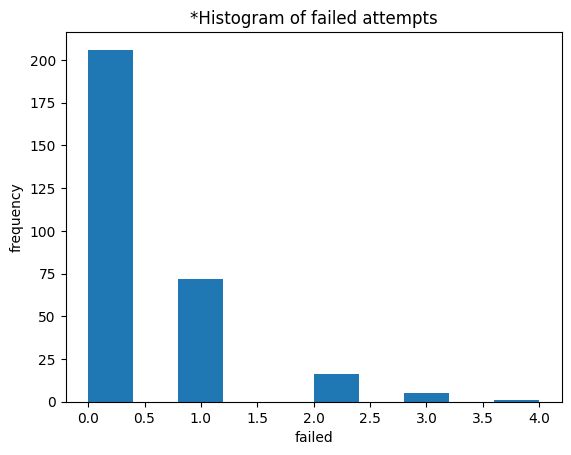

In [15]:
# Draw the histogram of failed_attempts.
plt.hist(log["failed_attempts"].dropna(), bins=10)

plt.xlabel("failed")
plt.ylabel("frequency")
plt.title("*Histogram of failed attempts")
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
 answer_q2 = "B"

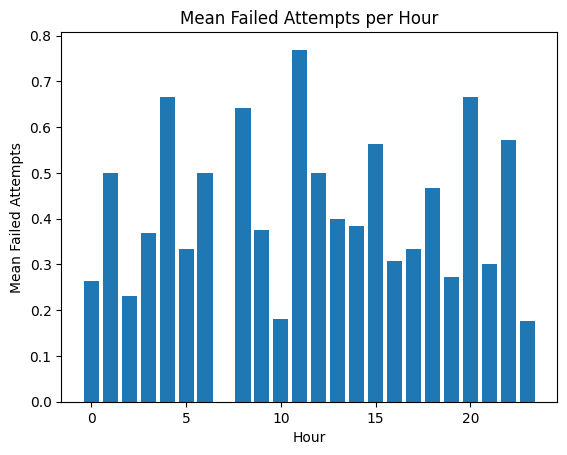

In [17]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
mean_failed_attempts = log.groupby("hour")["failed_attempts"].mean()

plt.bar(mean_failed_attempts.index, mean_failed_attempts.values)
plt.xlabel("Hour")
plt.ylabel("Mean Failed Attempts")
plt.title("Mean Failed Attempts per Hour")
plt.show()


In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:

# Please write a sentence response instead of code
It returns all rows of the third column of X.

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [ ]:
df.isnull().sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
A boxplot.

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
We scale features to put them on the same scale and prevent features with large values from dominating the model.

Commit the logins_clean.csv.(0.5 point)

In [19]:
# save the cleaned table in login_clean.csv
log_clean = log.copy()
log_clean["failed_attempts"] = log_clean["failed_attempts"].fillna(log_clean["failed_attempts"].median())

log_clean.to_csv("logins_clean.csv", index=False)
print("file saved successfully")

file saved successfully


In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
from sklearn.preprocessing import StandardScaler

cols = ["hour", "failed_attempts", "duration_min", "night"]

log_clean["night"] = (
    (log_clean["hour"] >= 22) |
    (log_clean["hour"] < 6)
).astype(int)
X = log_clean[cols].to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Shape of X:", X_scaled.shape)

In [ ]:
import numpy as np
import pandas as pd
